In [1]:
import pandas as pd
import numpy as np

veri = {
    'Telefon yaşı (yıl)': [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 0.2, 0.8, 1.2, 1.8, 
                           2.2, 2.8, 3.2, 3.8, 4.2, 4.8, 0.4, 0.9, 1.4, 1.9, 2.4, 3.1, 3.6, 4.3, 4.9],
    'İkinci el fiyatı (TL)': [40000, 34000, 29000, 25000, 22000, 19500, 18000, 16500, 15000, 14000, 13000, 
                             38000, 30500, 27500, 23000, 21000, 18500, 17500, 15500, 14500, 13200, 
                             36000, 29800, 26000, 22000, 20000, 18200, 17000, 14800, 13100]
}

df_telefon = pd.DataFrame(veri)
print("--- TELEFON VERİ SETİ İLK 5 SATIR ---")
print(df_telefon.head())

--- TELEFON VERİ SETİ İLK 5 SATIR ---
   Telefon yaşı (yıl)  İkinci el fiyatı (TL)
0                 0.0                  40000
1                 0.5                  34000
2                 1.0                  29000
3                 1.5                  25000
4                 2.0                  22000


In [2]:
ortalama_yas = df_telefon['Telefon yaşı (yıl)'].mean()
standart_sapma_fiyat = df_telefon['İkinci el fiyatı (TL)'].std()
print(f"Telefon Yaşları Ortalaması: {ortalama_yas:.2f} yıl")
print(f"İkinci El Fiyatları Standart Sapması: {standart_sapma_fiyat:.2f} TL")

Telefon Yaşları Ortalaması: 2.51 yıl
İkinci El Fiyatları Standart Sapması: 7853.45 TL


In [3]:
import numpy as np
fiyatlar_dizi = df_telefon['İkinci el fiyatı (TL)'].values
en_dusuk_fiyat = np.min(fiyatlar_dizi)
en_yuksek_fiyat = np.max(fiyatlar_dizi)
medyan_fiyat = np.median(fiyatlar_dizi)
ortalama_fiyat = np.mean(fiyatlar_dizi)

print(f"--- NUMPY İLE FİYAT İSTATİSTİKLERİ ---")
print(f"En Düşük Fiyat: {en_dusuk_fiyat:,.2f} TL")
print(f"En Yüksek Fiyat: {en_yuksek_fiyat:,.2f} TL")
print(f"Medyan (Ortanca) Fiyat: {medyan_fiyat:,.2f} TL")
print(f"Aritmetik Ortalama Fiyat: {ortalama_fiyat:,.2f} TL")

--- NUMPY İLE FİYAT İSTATİSTİKLERİ ---
En Düşük Fiyat: 13,000.00 TL
En Yüksek Fiyat: 40,000.00 TL
Medyan (Ortanca) Fiyat: 19,750.00 TL
Aritmetik Ortalama Fiyat: 22,070.00 TL


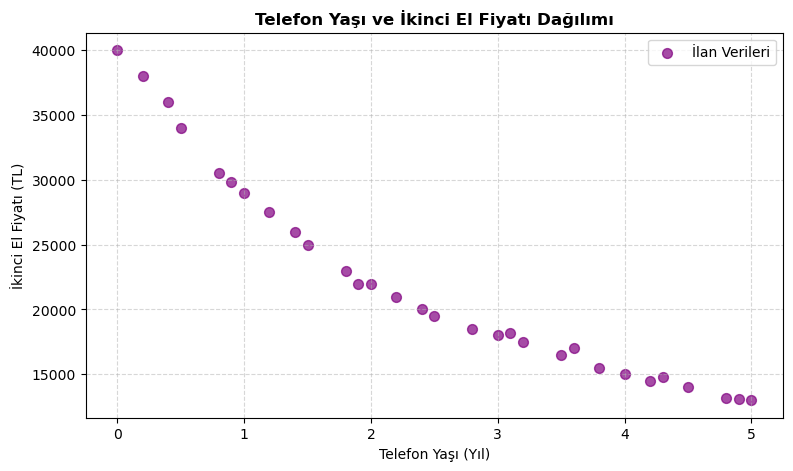

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.scatter(df_telefon['Telefon yaşı (yıl)'], df_telefon['İkinci el fiyatı (TL)'], 
            color='purple', alpha=0.7, s=50, label='İlan Verileri')
plt.title('Telefon Yaşı ve İkinci El Fiyatı Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Telefon Yaşı (Yıl)', fontsize=10)
plt.ylabel('İkinci El Fiyatı (TL)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression
X = df_telefon[['Telefon yaşı (yıl)']]
y = df_telefon['İkinci el fiyatı (TL)']
dogrusal_model = LinearRegression()
dogrusal_model.fit(X, y)

print("Doğrusal regresyon modeli başarıyla eğitildi!")
print(f"Öğrenilen Eğim (Katsayı/Coef): {dogrusal_model.coef_[0]:.2f}")
print(f"Öğrenilen Sabit Terim (Intercept): {dogrusal_model.intercept_:.2f}")

Doğrusal regresyon modeli başarıyla eğitildi!
Öğrenilen Eğim (Katsayı/Coef): -4912.24
Öğrenilen Sabit Terim (Intercept): 34416.09


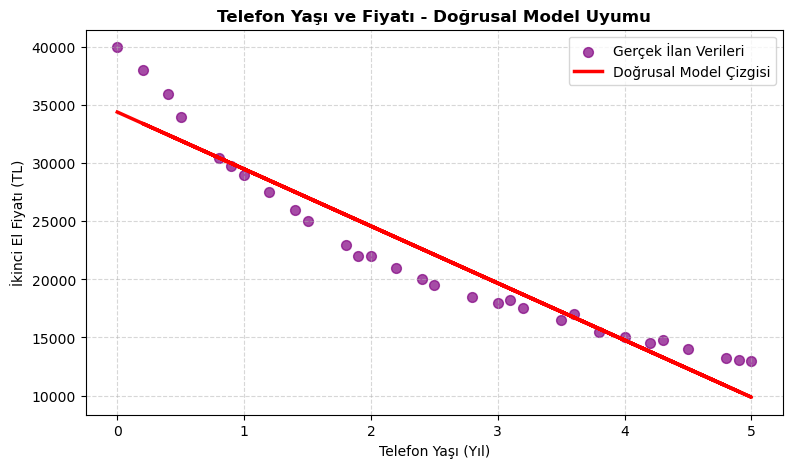

In [6]:
import matplotlib.pyplot as plt

y_pred_dogrusal = dogrusal_model.predict(X)
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color='purple', label='Gerçek İlan Verileri', alpha=0.7, s=50)
plt.plot(X, y_pred_dogrusal, color='red', linewidth=2.5, label='Doğrusal Model Çizgisi')
plt.title('Telefon Yaşı ve Fiyatı - Doğrusal Model Uyumu', fontsize=12, fontweight='bold')
plt.xlabel('Telefon Yaşı (Yıl)', fontsize=10)
plt.ylabel('İkinci El Fiyatı (TL)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [12]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

print("--- POLİNOMSEL GİRDİLER (X_poly) İLK 5 SATIR ---")
print("Format: [Sabit Sütun (1), Orijinal Yaş (X), Yaşın Karesi (X^2)]")
print(X_poly[:5])

--- POLİNOMSEL GİRDİLER (X_poly) İLK 5 SATIR ---
Format: [Sabit Sütun (1), Orijinal Yaş (X), Yaşın Karesi (X^2)]
[[1.   0.   0.  ]
 [1.   0.5  0.25]
 [1.   1.   1.  ]
 [1.   1.5  2.25]
 [1.   2.   4.  ]]


In [13]:
from sklearn.linear_model import LinearRegression
polinom_model = LinearRegression()
polinom_model.fit(X_poly, y)
print("İkinci dereceden polinom regresyon modeli başarıyla eğitildi!")
print(f"Öğrenilen Katsayılar (Coef): {polinom_model.coef_}")
print(f"Öğrenilen Sabit Terim (Intercept): {polinom_model.intercept_:.2f}")

İkinci dereceden polinom regresyon modeli başarıyla eğitildi!
Öğrenilen Katsayılar (Coef): [     0.         -10430.41520093   1086.26657376]
Öğrenilen Sabit Terim (Intercept): 38978.70


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


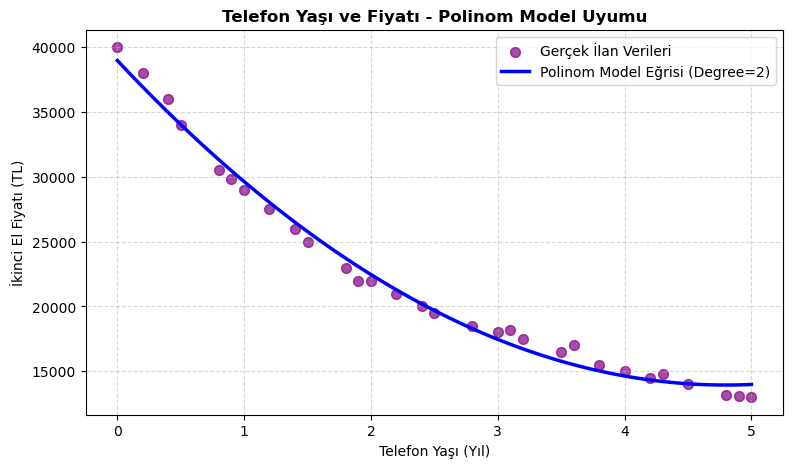

In [14]:
import numpy as np
import matplotlib.pyplot as plt

X_yeni = np.linspace(df_telefon['Telefon yaşı (yıl)'].min(), df_telefon['Telefon yaşı (yıl)'].max(), 100).reshape(-1, 1)
X_yeni_poly = poly.transform(X_yeni)
y_pred_polinom = polinom_model.predict(X_yeni_poly)
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color='purple', label='Gerçek İlan Verileri', alpha=0.7, s=50)
plt.plot(X_yeni, y_pred_polinom, color='blue', linewidth=2.5, label='Polinom Model Eğrisi (Degree=2)')
plt.title('Telefon Yaşı ve Fiyatı - Polinom Model Uyumu', fontsize=12, fontweight='bold')
plt.xlabel('Telefon Yaşı (Yıl)', fontsize=10)
plt.ylabel('İkinci El Fiyatı (TL)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [15]:
from sklearn.metrics import mean_squared_error, r2_score
y_pred_dogrusal = dogrusal_model.predict(X)
mse_dogrusal = mean_squared_error(y, y_pred_dogrusal)
r2_dogrusal = r2_score(y, y_pred_dogrusal)
y_pred_polinom = polinom_model.predict(X_poly)
mse_polinom = mean_squared_error(y, y_pred_polinom)
r2_polinom = r2_score(y, y_pred_polinom)

print("--- MODEL PERFORMANS KARŞILAŞTIRMASI ---")
print("1. Doğrusal Model (Linear Regression):")
print(f"   - MSE (Hata Payı) : {mse_dogrusal:,.2f}")
print(f"   - R² Skoru (Başarı): {r2_dogrusal:.4f}")
print("\n2. Polinom Model (Degree = 2):")
print(f"   - MSE (Hata Payı) : {mse_polinom:,.2f}")
print(f"   - R² Skoru (Başarı): {r2_polinom:.4f}")

--- MODEL PERFORMANS KARŞILAŞTIRMASI ---
1. Doğrusal Model (Linear Regression):
   - MSE (Hata Payı) : 5,316,321.26
   - R² Skoru (Başarı): 0.9108

2. Polinom Model (Degree = 2):
   - MSE (Hata Payı) : 528,617.92
   - R² Skoru (Başarı): 0.9911


In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

poly_3 = PolynomialFeatures(degree=3)
X_poly_3 = poly_3.fit_transform(X)
polinom_model_3 = LinearRegression()
polinom_model_3.fit(X_poly_3, y)
y_pred_polinom_3 = polinom_model_3.predict(X_poly_3)
mse_polinom_3 = mean_squared_error(y, y_pred_polinom_3)
r2_polinom_3 = r2_score(y, y_pred_polinom_3)
print("--- 3. DERECEDEN POLİNOM MODEL PERFORMANSI ---")
print(f"   - MSE (Hata Payı) : {mse_polinom_3:,.2f}")
print(f"   - R² Skoru (Başarı): {r2_polinom_3:.4f}")

--- 3. DERECEDEN POLİNOM MODEL PERFORMANSI ---
   - MSE (Hata Payı) : 93,649.07
   - R² Skoru (Başarı): 0.9984


In [19]:
import pandas as pd
yeni_telefon_df = pd.DataFrame({'Telefon yaşı (yıl)': [2.5]})
tahmin_dogrusal = dogrusal_model.predict(yeni_telefon_df)
yeni_telefon_poly = poly.transform(yeni_telefon_df)
tahmin_polinom = polinom_model.predict(yeni_telefon_poly)
print(f"Doğrusal Model Tahmini         : {tahmin_dogrusal[0]:,.2f} TL")
print(f"Polinom Model Tahmini (Degree=2): {tahmin_polinom[0]:,.2f} TL")

Doğrusal Model Tahmini         : 22,135.50 TL
Polinom Model Tahmini (Degree=2): 19,691.83 TL
